# 🔀 Notebook 07 — RQ4: Multimodal Fusion (Early vs Late)

---

> **RQ4:** To what extent does the combination of ICG and ECG modalities outperform single-modality methods in the accuracy of estimation?

## Two Fusion Strategies

### A. Early Fusion (Input-level)
```
ICG window  ─┐
              ├── Channel-Concat → (B, 2, 200) → Shared CNN-LSTM → [PEP, LVET]
ECG window  ─┘
```
Both signals processed jointly by the same network. The model learns cross-modal patterns implicitly through shared convolutions.

### B. Late Fusion (Feature-level)
```
ICG window → CNN Encoder (128) ─┐
                                 ├── Concatenate → FC Head → [PEP, LVET]
ECG window → CNN Encoder (128) ─┘
```
Two independent encoders; features merged only at the regression head. Each modality develops its own representation.

## Comparison
| Model | Input | Fusion |
|---|---|---|
| ICG-only CNN-LSTM | (B,1,200) | None |
| ECG-only CNN-LSTM | (B,1,200) | None |
| Early Fusion | (B,2,200) | Input concat |
| Late Fusion | (B,1,200)×2 | Feature concat |

## LOSO evaluation
One subject (`CHC14`, matching Notebook 06) is permanently reserved as a fixed
development set for early-stopping model selection — never a test subject, never
in any fold's training data. The remaining subjects rotate as outer test folds,
so RQ3/RQ4/RQ5 aggregate over the identical population and are directly
comparable.

---
**Requires:** `./output/final_dataset/` and CNN-LSTM from Notebook 06 (reused)

In [1]:
FINAL_DATASET_DIR = './output/final_dataset'
RESULTS_DIR_RQ3   = './output/results/rq3_single_modality'
RESULTS_DIR       = './output/results/rq4_multimodal_fusion'

import os
os.makedirs(f'{RESULTS_DIR}/figures', exist_ok=True)
os.makedirs(f'{RESULTS_DIR}/checkpoints', exist_ok=True)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json, warnings, time
from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR


warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': 0.3, 'font.size': 11})

device = torch.device('cuda' if torch.cuda.is_available() else
                      'mps' if torch.backends.mps.is_available() else 'cpu')
print(f'Device: {device}')

np.random.seed(42); torch.manual_seed(42)
if device.type == 'cuda': torch.cuda.manual_seed(42)

HP = {
    # T=200 matches Notebook 02/03's WIN_SAMPLES (actual beat-window length);
    # overridden below from the data shape as a safety check. 256 was a leftover
    # from the proposal's original Ri-to-Ri+1 padding scheme (see Notebook 06).
    'T': 200, 'batch_size': 64, 'epochs': 100, 'lr': 1e-3,
    'weight_decay': 1e-4, 'huber_delta': 10.0, 'dropout': 0.3,
    'lstm_hidden': 128, 'lstm_layers': 2,
}

Device: cpu


In [3]:
base = Path(FINAL_DATASET_DIR)


def load_all():
    splits = {}
    for s in ['train', 'val', 'test']:
        d = base / s
        splits[s] = {
            'X_icg':  np.load(d/'X_icg.npy'),
            'X_ecg':  np.load(d/'X_ecg.npy'),
            'X_multi':np.load(d/'X_multi.npy'),
            'y_pep':  np.load(d/'y_pep.npy'),
            'y_lvet': np.load(d/'y_lvet.npy'),
            'meta':   pd.read_csv(d/'meta.csv'),
        }
    return splits


splits   = load_all()
meta_all = pd.concat([splits['train']['meta'], splits['val']['meta']], ignore_index=True)
subjects = meta_all['subject_id'].values
unique_subj = np.unique(subjects)


# All arrays for LOSO
def cat(key): return np.concatenate([splits['train'][key], splits['val'][key]], axis=0)

X_icg_all  = cat('X_icg')
X_ecg_all  = cat('X_ecg')
X_multi_all= cat('X_multi')   # shape: (N, 2, 200)
y_pep_all  = cat('y_pep')
y_lvet_all = cat('y_lvet')

# Pin T to the actual window length rather than a stale constant (see Notebook 06).
HP['T'] = X_icg_all.shape[-1]
print(f"HP['T'] set to actual window length: {HP['T']} samples (no padding)")

print(f'ICG shape:   {X_icg_all.shape}')
print(f'ECG shape:   {X_ecg_all.shape}')
print(f'Multi shape: {X_multi_all.shape}  ← early fusion input')
print(f'Subjects: {unique_subj}')

# ── Reserve the SAME fixed dev subject as Notebook 06, for RQ3/RQ4/RQ5 comparability ──
# Without this, early stopping would peek at the fold's own test subject (leakage,
# identical to the Notebook 06 bug), AND RQ4's aggregate would be computed over a
# different population of subjects than RQ3's (11 vs 10), confounding any
# "fusion beats ICG-only" comparison with a population mismatch on top of the leakage.
print(pd.Series(subjects).value_counts())

DEV_SUBJECT = 'CHC14'  # must match Notebook 06 exactly, for RQ3/RQ4/RQ5 comparability
loso_test_subjects = [s for s in unique_subj if s != DEV_SUBJECT]

print(f'\nDev subject (early-stopping only; never trained or tested on as a fold): '
      f'{DEV_SUBJECT} ({(subjects == DEV_SUBJECT).sum()} beats)')
print(f'LOSO test subjects ({len(loso_test_subjects)}): {loso_test_subjects}')

HP['T'] set to actual window length: 200 samples (no padding)
ICG shape:   (210, 200)
ECG shape:   (210, 200)
Multi shape: (210, 2, 200)  ← early fusion input
Subjects: ['CHC01' 'CHC02' 'CHC04' 'CHC05' 'CHC06' 'CHC07' 'CHC08' 'CHC09' 'CHC10'
 'CHC12' 'CHC14']
CHC14    44
CHC10    33
CHC07    22
CHC12    22
CHC02    18
CHC05    18
CHC09    17
CHC04    13
CHC01     9
CHC08     8
CHC06     6
Name: count, dtype: int64

Dev subject (early-stopping only; never trained or tested on as a fold): CHC14 (44 beats)
LOSO test subjects (10): ['CHC01', 'CHC02', 'CHC04', 'CHC05', 'CHC06', 'CHC07', 'CHC08', 'CHC09', 'CHC10', 'CHC12']


## 1. Flexible Dataset Class

In [4]:
class HeartCycleMultiModalDataset(Dataset):
    """
    Supports single-modality and multimodal inputs.
    For late fusion, returns (X_icg, X_ecg, y).
    For early fusion / single-modal, returns (X, y).
    """
    def __init__(self, X_primary, y_pep, y_lvet, T=200, X_secondary=None):
        self.dual = X_secondary is not None
        self.T = T

        def prep(X):
            if X.ndim == 2: X = X[:, np.newaxis, :]
            ol = X.shape[2]
            if ol < T:
                pad = np.zeros((len(X), X.shape[1], T-ol), dtype=np.float32)
                X = np.concatenate([X, pad], axis=2)
            elif ol > T: X = X[:, :, :T]
            return torch.tensor(X, dtype=torch.float32)

        self.X1 = prep(X_primary)
        self.X2 = prep(X_secondary) if self.dual else None
        self.y  = torch.tensor(np.stack([y_pep, y_lvet], axis=1), dtype=torch.float32)


    def __len__(self): return len(self.X1)


    def __getitem__(self, idx):
        if self.dual:
            return self.X1[idx], self.X2[idx], self.y[idx]
        return self.X1[idx], self.y[idx]


print('Dataset class ready.')

Dataset class ready.


## 2. Early Fusion Model — Channel Concatenation

In [5]:
class ConvBlock1D(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size, pool=True):
        super().__init__()
        layers = [
            nn.Conv1d(in_ch, out_ch, kernel_size, padding=kernel_size//2, bias=False),
            nn.BatchNorm1d(out_ch), nn.ReLU(inplace=True),
        ]
        if pool: layers.append(nn.MaxPool1d(2))
        self.block = nn.Sequential(*layers)
    def forward(self, x): return self.block(x)


class EarlyFusionCNNLSTM(nn.Module):
    """
    Early Fusion: ICG + ECG concatenated as 2-channel input.
    Input: (B, 2, T)  — channel 0 = ICG, channel 1 = ECG
    """
    def __init__(self, in_channels=2, T=200, lstm_hidden=128, lstm_layers=2, dropout=0.3):
        super().__init__()
        # Same CNN-LSTM but takes 2-channel input
        self.cnn = nn.Sequential(
            ConvBlock1D(in_channels, 32,  7, pool=True),
            ConvBlock1D(32,          64,  5, pool=True),
            ConvBlock1D(64,          128, 3, pool=False),
        )
        self.lstm = nn.LSTM(128, lstm_hidden, lstm_layers,
                            batch_first=True, bidirectional=True,
                            dropout=dropout if lstm_layers > 1 else 0.0)
        self.head = nn.Sequential(
            nn.Linear(lstm_hidden*2, 256), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(256, 128),           nn.ReLU(), nn.Dropout(dropout*0.5),
            nn.Linear(128, 2),
        )
        self._init_weights()


    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv1d): nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
            elif isinstance(m, nn.Linear): nn.init.xavier_uniform_(m.weight)


    def forward(self, x):
        # x: (B, 2, T)
        feat = self.cnn(x)                # (B, 128, T//4)
        feat = feat.permute(0, 2, 1)      # (B, T//4, 128)
        out, _ = self.lstm(feat)          # (B, T//4, 256)
        return self.head(out.mean(dim=1)) # (B, 2)


# Test
dummy2 = torch.zeros(4, 2, HP['T'])
ef = EarlyFusionCNNLSTM(in_channels=2, T=HP['T'])
print(f'Early Fusion output: {ef(dummy2).shape}')
print(f'Params: {sum(p.numel() for p in ef.parameters() if p.requires_grad):,}')

Early Fusion output: torch.Size([4, 2])
Params: 794,114


## 3. Late Fusion Model — Independent Encoders + Feature Concat

In [6]:
class SingleStreamEncoder(nn.Module):
    """CNN encoder for one modality."""
    def __init__(self, in_ch=1, out_dim=128, dropout=0.3):
        super().__init__()
        self.cnn = nn.Sequential(
            ConvBlock1D(in_ch, 32,  7, pool=True),
            ConvBlock1D(32,    64,  5, pool=True),
            ConvBlock1D(64,    128, 3, pool=False),
        )
        self.lstm = nn.LSTM(128, out_dim//2, 2, batch_first=True, bidirectional=True,
                            dropout=dropout)
        # output: out_dim features per stream
    def forward(self, x):
        f = self.cnn(x).permute(0, 2, 1)
        out, _ = self.lstm(f)
        return out.mean(dim=1)  # (B, out_dim)


class LateFusionModel(nn.Module):
    """
    Late Fusion: Two independent CNN-LSTM encoders, feature-level concat.
    ICG encoder  → f_icg (B, 128)
    ECG encoder  → f_ecg (B, 128)
    Concat       → (B, 256) → FC Head → [PEP, LVET]
    """
    def __init__(self, encoder_dim=128, dropout=0.3):
        super().__init__()
        self.icg_encoder = SingleStreamEncoder(1, encoder_dim, dropout)
        self.ecg_encoder = SingleStreamEncoder(1, encoder_dim, dropout)
        self.head = nn.Sequential(
            nn.Linear(encoder_dim * 2, 256), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(256, 128),             nn.ReLU(), nn.Dropout(dropout*0.5),
            nn.Linear(128, 2),
        )
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear): nn.init.xavier_uniform_(m.weight)

    def forward(self, x_icg, x_ecg):
        # x_icg, x_ecg: (B, 1, T)
        f_icg = self.icg_encoder(x_icg)          # (B, 128)
        f_ecg = self.ecg_encoder(x_ecg)          # (B, 128)
        fused = torch.cat([f_icg, f_ecg], dim=1) # (B, 256)
        return self.head(fused)                   # (B, 2)


# Test
lf = LateFusionModel()
d1 = torch.zeros(4, 1, HP['T'])
d2 = torch.zeros(4, 1, HP['T'])
print(f'Late Fusion output: {lf(d1, d2).shape}')
print(f'Params: {sum(p.numel() for p in lf.parameters() if p.requires_grad):,}')

Late Fusion output: torch.Size([4, 2])
Params: 567,234


## 4. Training Functions for Both Fusion Types

In [7]:
def train_early_fusion_epoch(model, loader, opt, loss_fn, device):
    model.train()
    total = 0
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        opt.zero_grad(set_to_none=True)
        p = model(X)
        loss = loss_fn(p, y)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        total += loss.item() * len(X)
    return total / len(loader.dataset)


def train_late_fusion_epoch(model, loader, opt, loss_fn, device):
    model.train()
    total = 0
    for X_icg, X_ecg, y in loader:
        X_icg, X_ecg, y = X_icg.to(device), X_ecg.to(device), y.to(device)
        opt.zero_grad(set_to_none=True)
        p = model(X_icg, X_ecg)
        loss = loss_fn(p, y)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        total += loss.item() * len(X_icg)
    return total / len(loader.dataset)


@torch.no_grad()
def eval_early_fusion(model, loader, loss_fn, device):
    model.eval()
    preds_all, true_all = [], []
    for X, y in loader:
        preds_all.append(model(X.to(device)).cpu().numpy())
        true_all.append(y.numpy())
    return np.concatenate(preds_all), np.concatenate(true_all)


@torch.no_grad()
def eval_late_fusion(model, loader, device):
    model.eval()
    preds_all, true_all = [], []
    for X_icg, X_ecg, y in loader:
        preds_all.append(model(X_icg.to(device), X_ecg.to(device)).cpu().numpy())
        true_all.append(y.numpy())
    return np.concatenate(preds_all), np.concatenate(true_all)


def metrics(true, pred):
    r = {}
    for i, n in enumerate(['PEP', 'LVET']):
        t, p = true[:, i], pred[:, i]
        r[f'{n}_MAE']  = mean_absolute_error(t, p)
        r[f'{n}_RMSE'] = np.sqrt(mean_squared_error(t, p))
        r[f'{n}_R2']   = r2_score(t, p)
        r[f'{n}_w7']   = np.mean(np.abs(p-t) < 7)  * 100
        r[f'{n}_w15']  = np.mean(np.abs(p-t) < 15) * 100
    return r

print('Training functions ready.')

Training functions ready.


## 5. Run Early Fusion LOSO

In [8]:
def loso_early_fusion(X_multi, y_pep, y_lvet, subjects, HP, device, dev_subject=None):
    """
    LOSO for Early Fusion. If dev_subject is given, it is permanently reserved as
    a fixed development set for early-stopping model selection — never a test
    subject, never in any fold's training data (identical pattern to Notebook 06,
    for the same reason: peeking at the test subject to choose "best epoch" is
    leakage even though the model never backprops on it).
    """
    unique_subj = np.unique(subjects)
    test_subjects = [s for s in unique_subj if s != dev_subject] if dev_subject is not None else list(unique_subj)
    loss_fn = nn.HuberLoss(delta=HP['huber_delta'])
    all_preds = np.zeros((len(y_pep), 2))
    all_true  = np.zeros((len(y_pep), 2))
    fold_res  = []

    # Fixed dev set for early stopping — built once, identical across every fold.
    dev_ld = None
    if dev_subject is not None:
        dev_mask = (subjects == dev_subject)
        dev_ds = HeartCycleMultiModalDataset(X_multi[dev_mask], y_pep[dev_mask], y_lvet[dev_mask], HP['T'])
        dev_ld = DataLoader(dev_ds, HP['batch_size']*2, shuffle=False, num_workers=0)
    else:
        print('  ⚠️  No dev_subject given — early stopping will use the TEST subject itself (leaky).')

    for fi, subj in enumerate(test_subjects):
        print(f'  Fold {fi+1}/{len(test_subjects)} — {subj}', end=' ')
        tm = (subjects == subj); trm = ~tm
        if dev_subject is not None:
            trm &= (subjects != dev_subject)  # dev subject never trained on

        tr_ds = HeartCycleMultiModalDataset(X_multi[trm], y_pep[trm], y_lvet[trm], HP['T'])
        te_ds = HeartCycleMultiModalDataset(X_multi[tm],  y_pep[tm],  y_lvet[tm],  HP['T'])
        tr_ld = DataLoader(tr_ds, HP['batch_size'], shuffle=True,  num_workers=0, pin_memory=(device.type=='cuda'))
        te_ld = DataLoader(te_ds, HP['batch_size']*2, shuffle=False, num_workers=0)
        es_ld = dev_ld if dev_ld is not None else te_ld

        model = EarlyFusionCNNLSTM(in_channels=2, T=HP['T'],
                                   lstm_hidden=HP['lstm_hidden'],
                                   lstm_layers=HP['lstm_layers'],
                                   dropout=HP['dropout']).to(device)
        opt   = AdamW(model.parameters(), lr=HP['lr'], weight_decay=HP['weight_decay'])
        sched = CosineAnnealingLR(opt, T_max=HP['epochs'], eta_min=1e-5)

        best_mae, best_state, best_epoch, patience = float('inf'), None, None, 0
        for epoch in range(HP['epochs']):
            train_early_fusion_epoch(model, tr_ld, opt, loss_fn, device)
            preds, true = eval_early_fusion(model, es_ld, loss_fn, device)
            sched.step()
            avg_mae = (mean_absolute_error(true[:,0], preds[:,0]) +
                       mean_absolute_error(true[:,1], preds[:,1])) / 2
            if avg_mae < best_mae:
                best_mae = avg_mae
                best_state = {k: v.clone() for k, v in model.state_dict().items()}
                best_epoch = epoch + 1
                patience = 0
            else:
                patience += 1
                if patience >= 20: break

        # Load the dev-selected best weights, then evaluate ONCE on the held-out
        # test subject — the test subject never influenced which epoch was kept.
        model.load_state_dict(best_state)
        preds, true = eval_early_fusion(model, te_ld, loss_fn, device)
        all_preds[tm] = preds; all_true[tm] = true
        m = metrics(true, preds); m['subject'] = subj; m['best_epoch'] = best_epoch
        fold_res.append(m)
        print(f'→ PEP:{m["PEP_MAE"]:.1f}ms LVET:{m["LVET_MAE"]:.1f}ms')

    # The reserved dev subject's rows in all_preds/all_true are never written
    # (it's never a test subject) and stay at their zero initialization — exclude
    # them explicitly so they can't silently corrupt the aggregate metrics.
    agg_mask = (subjects != dev_subject) if dev_subject is not None else np.ones(len(y_pep), dtype=bool)
    agg_metrics = metrics(all_true[agg_mask], all_preds[agg_mask])
    agg_metrics['dev_subject'] = dev_subject
    agg_metrics['loso_test_subjects'] = test_subjects

    return pd.DataFrame(fold_res), agg_metrics, all_preds, all_true


print('Running Early Fusion LOSO...')
ef_folds, ef_agg, ef_preds, ef_true = loso_early_fusion(
    X_multi_all, y_pep_all, y_lvet_all, subjects, HP, device,
    dev_subject=DEV_SUBJECT,   # fixed early-stopping subject — never trained or tested on
)

print(f'\nEARLY FUSION: PEP MAE={ef_agg["PEP_MAE"]:.2f}ms | LVET MAE={ef_agg["LVET_MAE"]:.2f}ms')

Running Early Fusion LOSO...
  Fold 1/10 — CHC01 

→ PEP:9.7ms LVET:4.3ms
  Fold 2/10 — CHC02 

→ PEP:16.6ms LVET:33.4ms
  Fold 3/10 — CHC04 

→ PEP:13.2ms LVET:11.0ms
  Fold 4/10 — CHC05 

→ PEP:17.0ms LVET:67.2ms
  Fold 5/10 — CHC06 

...

→ PEP:21.3ms LVET:29.3ms
  Fold 7/10 — CHC08 

→ PEP:23.5ms LVET:11.9ms
  Fold 8/10 — CHC09 

→ PEP:9.7ms LVET:21.7ms
  Fold 9/10 — CHC10 

→ PEP:4.2ms LVET:14.9ms
  Fold 10/10 — CHC12 

→ PEP:10.8ms LVET:43.7ms

EARLY FUSION: PEP MAE=12.76ms | LVET MAE=28.25ms


In [9]:
def loso_late_fusion(X_icg, X_ecg, y_pep, y_lvet, subjects, HP, device, dev_subject=None):
    """
    LOSO for Late Fusion. Same fixed-dev-subject early-stopping pattern as
    loso_early_fusion / Notebook 06 — see that docstring for the rationale.
    """
    unique_subj = np.unique(subjects)
    test_subjects = [s for s in unique_subj if s != dev_subject] if dev_subject is not None else list(unique_subj)
    loss_fn = nn.HuberLoss(delta=HP['huber_delta'])
    all_preds = np.zeros((len(y_pep), 2))
    all_true  = np.zeros((len(y_pep), 2))
    fold_res  = []

    # Fixed dev set for early stopping — built once, identical across every fold.
    dev_ld = None
    if dev_subject is not None:
        dev_mask = (subjects == dev_subject)
        dev_ds = HeartCycleMultiModalDataset(X_icg[dev_mask], y_pep[dev_mask], y_lvet[dev_mask], HP['T'], X_ecg[dev_mask])
        dev_ld = DataLoader(dev_ds, HP['batch_size']*2, shuffle=False, num_workers=0)
    else:
        print('  ⚠️  No dev_subject given — early stopping will use the TEST subject itself (leaky).')

    for fi, subj in enumerate(test_subjects):
        print(f'  Fold {fi+1}/{len(test_subjects)} — {subj}', end=' ')
        tm = (subjects == subj); trm = ~tm
        if dev_subject is not None:
            trm &= (subjects != dev_subject)  # dev subject never trained on

        tr_ds = HeartCycleMultiModalDataset(X_icg[trm], y_pep[trm], y_lvet[trm], HP['T'], X_ecg[trm])
        te_ds = HeartCycleMultiModalDataset(X_icg[tm],  y_pep[tm],  y_lvet[tm],  HP['T'], X_ecg[tm])
        tr_ld = DataLoader(tr_ds, HP['batch_size'], shuffle=True,  num_workers=0, pin_memory=(device.type=='cuda'))
        te_ld = DataLoader(te_ds, HP['batch_size']*2, shuffle=False, num_workers=0)
        es_ld = dev_ld if dev_ld is not None else te_ld

        model = LateFusionModel(encoder_dim=128, dropout=HP['dropout']).to(device)
        opt   = AdamW(model.parameters(), lr=HP['lr'], weight_decay=HP['weight_decay'])
        sched = CosineAnnealingLR(opt, T_max=HP['epochs'], eta_min=1e-5)

        best_mae, best_state, best_epoch, patience = float('inf'), None, None, 0
        for epoch in range(HP['epochs']):
            train_late_fusion_epoch(model, tr_ld, opt, loss_fn, device)
            preds, true = eval_late_fusion(model, es_ld, device)
            sched.step()
            avg_mae = (mean_absolute_error(true[:,0], preds[:,0]) +
                       mean_absolute_error(true[:,1], preds[:,1])) / 2
            if avg_mae < best_mae:
                best_mae = avg_mae
                best_state = {k: v.clone() for k, v in model.state_dict().items()}
                best_epoch = epoch + 1
                patience = 0
            else:
                patience += 1
                if patience >= 20: break

        # Load the dev-selected best weights, then evaluate ONCE on the held-out
        # test subject — the test subject never influenced which epoch was kept.
        model.load_state_dict(best_state)
        preds, true = eval_late_fusion(model, te_ld, device)
        all_preds[tm] = preds; all_true[tm] = true
        m = metrics(true, preds); m['subject'] = subj; m['best_epoch'] = best_epoch
        fold_res.append(m)
        print(f'→ PEP:{m["PEP_MAE"]:.1f}ms LVET:{m["LVET_MAE"]:.1f}ms')

    # The reserved dev subject's rows in all_preds/all_true are never written
    # (it's never a test subject) and stay at their zero initialization — exclude
    # them explicitly so they can't silently corrupt the aggregate metrics.
    agg_mask = (subjects != dev_subject) if dev_subject is not None else np.ones(len(y_pep), dtype=bool)
    agg_metrics = metrics(all_true[agg_mask], all_preds[agg_mask])
    agg_metrics['dev_subject'] = dev_subject
    agg_metrics['loso_test_subjects'] = test_subjects

    return pd.DataFrame(fold_res), agg_metrics, all_preds, all_true

print('Running Late Fusion LOSO...')
lf_folds, lf_agg, lf_preds, lf_true = loso_late_fusion(
    X_icg_all, X_ecg_all, y_pep_all, y_lvet_all, subjects, HP, device,
    dev_subject=DEV_SUBJECT,   # fixed early-stopping subject — never trained or tested on
)

print(f'\nLATE FUSION: PEP MAE={lf_agg["PEP_MAE"]:.2f}ms | LVET MAE={lf_agg["LVET_MAE"]:.2f}ms')

Running Late Fusion LOSO...
  Fold 1/10 — CHC01 

→ PEP:8.4ms LVET:6.8ms
  Fold 2/10 — CHC02 

→ PEP:18.1ms LVET:25.2ms
  Fold 3/10 — CHC04 

→ PEP:15.7ms LVET:12.8ms
  Fold 4/10 — CHC05 

→ PEP:21.8ms LVET:66.3ms
  Fold 5/10 — CHC06 

...

→ PEP:12.1ms LVET:21.9ms
  Fold 7/10 — CHC08 

→ PEP:14.3ms LVET:11.1ms
  Fold 8/10 — CHC09 

→ PEP:5.8ms LVET:17.2ms
  Fold 9/10 — CHC10 

→ PEP:8.7ms LVET:16.1ms
  Fold 10/10 — CHC12 

→ PEP:12.6ms LVET:49.4ms

LATE FUSION: PEP MAE=12.88ms | LVET MAE=26.57ms


## 6. Full Model Comparison — RQ4 Answer


=== RQ4: MULTIMODAL FUSION COMPARISON ===
(All three aggregated over the same 10 LOSO test subjects, CHC14 reserved as dev subject throughout)
Model                        PEP MAE   LVET MAE   PEP R²   w/15ms PEP
----------------------------------------------------------------------
ICG-only CNN-LSTM              12.44      25.12   -0.625        62.7%
Early Fusion                   12.76      28.25   -0.831        57.8%
Late Fusion                    12.88      26.57   -0.806        65.1%


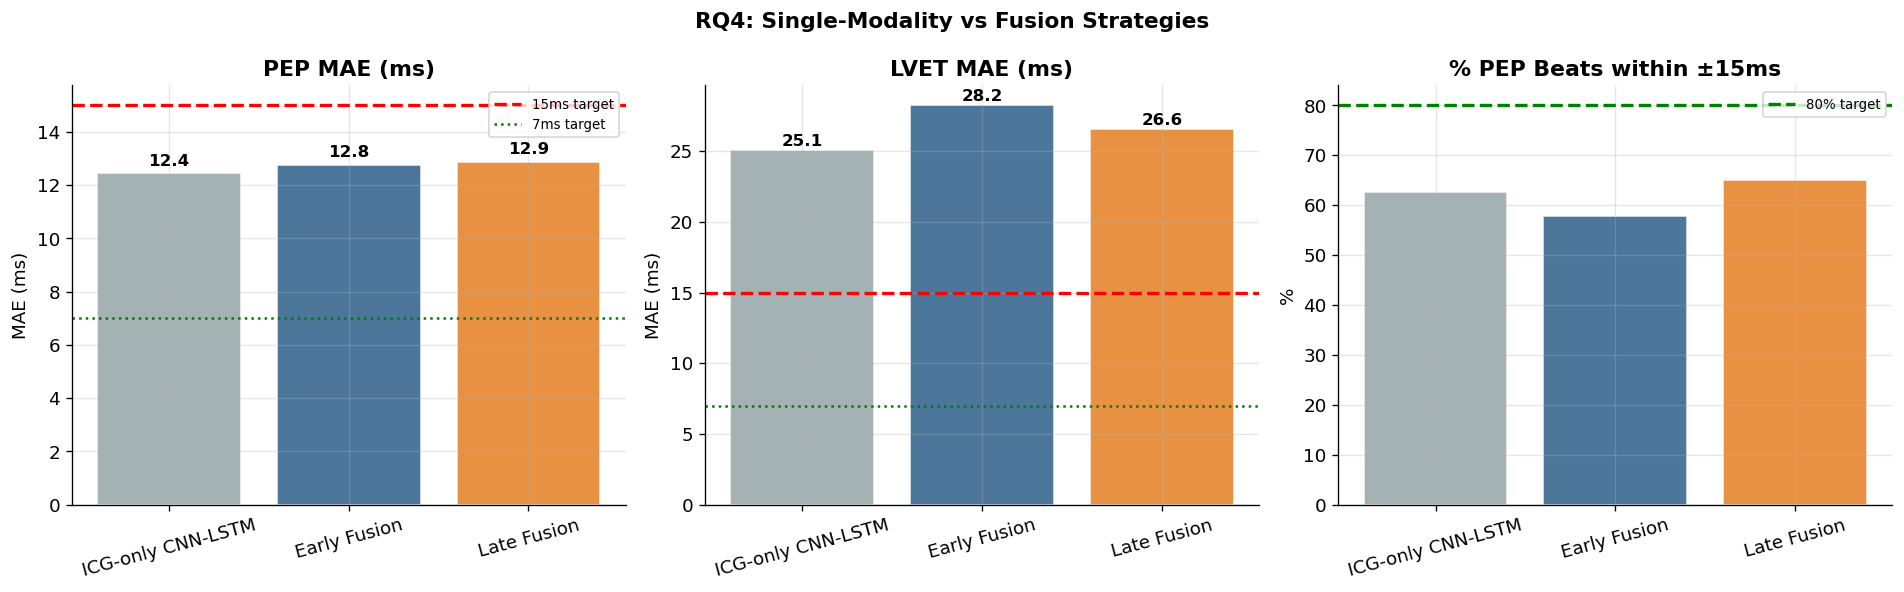


✅ RQ4 COMPLETE. Best fusion strategy identified.
NEXT: Notebook 08 — RQ5 Cross-Modal Attention Architecture (THE NOVEL CONTRIBUTION)


In [10]:
# Load RQ3 CNN-LSTM results
# NB06 saves the RAW, full-length preds/true arrays (aligned 1:1 with `subjects`),
# and the reserved dev subject's rows in them are never written — they sit at
# their zero initialization. Must mask those out with the SAME DEV_SUBJECT before
# recomputing metrics, or they silently corrupt icg_agg with fake (0,0) pairs —
# exactly the kind of population mismatch this fix is about.
try:
    cnnlstm_preds = np.load(f'{RESULTS_DIR_RQ3}/cnnlstm_loso_preds.npy')
    cnnlstm_true  = np.load(f'{RESULTS_DIR_RQ3}/cnnlstm_loso_true.npy')
    icg_agg_mask = subjects != DEV_SUBJECT
    icg_agg = metrics(cnnlstm_true[icg_agg_mask], cnnlstm_preds[icg_agg_mask])
except:
    icg_agg = {'PEP_MAE': 999, 'LVET_MAE': 999, 'PEP_R2': 0, 'LVET_R2': 0,
                'PEP_w15': 0, 'LVET_w15': 0}
    print('RQ3 results not found — run Notebook 06 first')

comparison = {
    'ICG-only CNN-LSTM': icg_agg,
    'Early Fusion':       ef_agg,
    'Late Fusion':        lf_agg,
}

print('\n=== RQ4: MULTIMODAL FUSION COMPARISON ===')
print(f'(All three aggregated over the same {len(loso_test_subjects)} LOSO test subjects, '
      f'{DEV_SUBJECT} reserved as dev subject throughout)')
print(f'{"Model":<25} {"PEP MAE":>10} {"LVET MAE":>10} {"PEP R²":>8} {"w/15ms PEP":>12}')
print('-'*70)
for name, m in comparison.items():
    print(f'{name:<25} {m["PEP_MAE"]:>10.2f} {m["LVET_MAE"]:>10.2f} '
          f'{m["PEP_R2"]:>8.3f} {m["PEP_w15"]:>11.1f}%')

# Visualize
model_names = list(comparison.keys())
pep_maes    = [comparison[m]['PEP_MAE']  for m in model_names]
lvet_maes   = [comparison[m]['LVET_MAE'] for m in model_names]
pep_w15     = [comparison[m]['PEP_w15']  for m in model_names]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('RQ4: Single-Modality vs Fusion Strategies', fontsize=13, fontweight='bold')
colors = ['#95A5A6', '#2C5F8A', '#E67E22']

axes[0].bar(model_names, pep_maes, color=colors, alpha=0.85, edgecolor='white')
axes[0].axhline(15, color='red', linewidth=2, linestyle='--', label='15ms target')
axes[0].axhline(7,  color='green', linewidth=1.5, linestyle=':', label='7ms target')
axes[0].set_title('PEP MAE (ms)', fontweight='bold'); axes[0].set_ylabel('MAE (ms)')
axes[0].tick_params(axis='x', rotation=15); axes[0].legend(fontsize=8)
for i, v in enumerate(pep_maes):
    axes[0].text(i, v+0.3, f'{v:.1f}', ha='center', fontweight='bold', fontsize=10)

axes[1].bar(model_names, lvet_maes, color=colors, alpha=0.85, edgecolor='white')
axes[1].axhline(15, color='red', linewidth=2, linestyle='--')
axes[1].axhline(7,  color='green', linewidth=1.5, linestyle=':')
axes[1].set_title('LVET MAE (ms)', fontweight='bold'); axes[1].set_ylabel('MAE (ms)')
axes[1].tick_params(axis='x', rotation=15)
for i, v in enumerate(lvet_maes):
    axes[1].text(i, v+0.3, f'{v:.1f}', ha='center', fontweight='bold', fontsize=10)

axes[2].bar(model_names, pep_w15, color=colors, alpha=0.85, edgecolor='white')
axes[2].axhline(80, color='green', linewidth=2, linestyle='--', label='80% target')
axes[2].set_title('% PEP Beats within ±15ms', fontweight='bold'); axes[2].set_ylabel('%')
axes[2].tick_params(axis='x', rotation=15); axes[2].legend(fontsize=8)

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/figures/rq4_fusion_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

# Save results
np.save(f'{RESULTS_DIR}/early_fusion_preds.npy', ef_preds)
np.save(f'{RESULTS_DIR}/late_fusion_preds.npy',  lf_preds)
ef_folds.to_csv(f'{RESULTS_DIR}/early_fusion_folds.csv', index=False)
lf_folds.to_csv(f'{RESULTS_DIR}/late_fusion_folds.csv',  index=False)

print('\n✅ RQ4 COMPLETE. Best fusion strategy identified.')
print('NEXT: Notebook 08 — RQ5 Cross-Modal Attention Architecture (THE NOVEL CONTRIBUTION)')